# 1 – Monte Carlo option pricing: the basics

**Big idea:** the fair price of an option is an **expected value**. We can't always compute it exactly,
so we **simulate many random outcomes and take the average**.

Only basic probability is needed:

| idea | where it shows up |
|---|---|
| random variable, normal distribution | the stock price at expiry, $S_T$ |
| expected value | the option price |
| Law of Large Numbers (LLN) | why the average of simulations works |
| Central Limit Theorem (CLT) | how accurate the average is (confidence interval) |

We check every Monte Carlo answer against the exact **Black–Scholes** formula.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Make the project's src/ folder importable whether we start in the root or in notebooks/.
project_root = Path.cwd().resolve()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src import black_scholes, monte_carlo, payoff, price_table, simulate_paths, simulate_terminal_prices

plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:,.4f}".format)
rng = np.random.default_rng(42)

## 1. The stock price at expiry is a random variable

We model the stock with **geometric Brownian motion**. The price $T$ years from now is

$$S_T = S_0 \, e^{(r - \frac{1}{2}\sigma^2)T + \sigma\sqrt{T}\,Z}, \qquad Z \sim \mathcal N(0, 1)$$

| symbol | meaning |
|---|---|
| $S_0$ | price today |
| $r$ | risk-free interest rate (per year) |
| $\sigma$ | volatility: how much the price jumps around (per year) |
| $T$ | time until the option expires (years) |
| $Z$ | a standard normal random number – **the only source of randomness** |

So $\ln S_T$ is **normal**, which makes $S_T$ **lognormal** (skewed to the right, never negative).
One fact we'll check: $E[S_T] = S_0 e^{rT}$.

In [2]:
S0 = 100.0     # price today
K = 100.0      # strike price
T = 1.0        # 1 year to expiry
r = 0.05       # 5% interest rate
sigma = 0.20   # 20% volatility

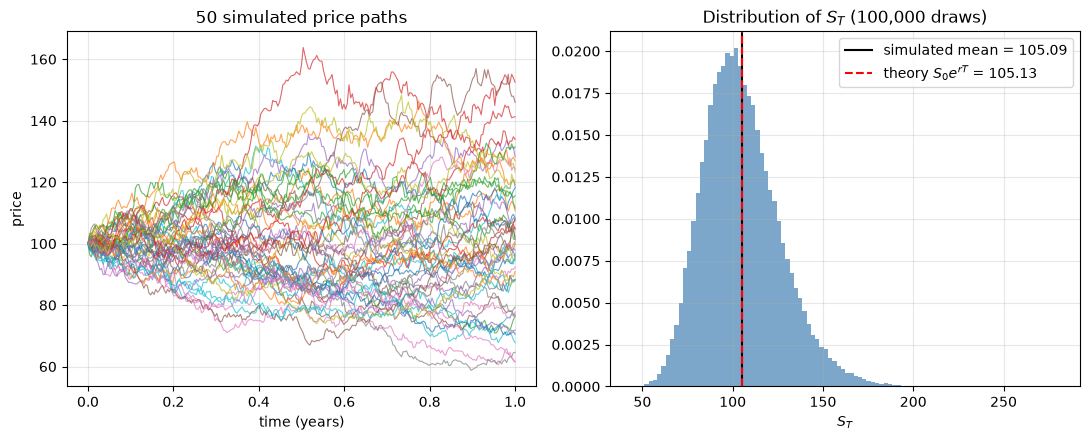

In [3]:
paths = simulate_paths(S0, r, sigma, T, n_steps=252, n_paths=50, rng=rng)
ST = simulate_terminal_prices(S0, r, sigma, T, 100_000, rng=rng)

fig, (ax1, ax2) = plt.subplots(1, 2)
ax1.plot(np.linspace(0, T, 253), paths.T, lw=0.8, alpha=0.7)
ax1.set(title="50 simulated price paths", xlabel="time (years)", ylabel="price")

ax2.hist(ST, bins=100, density=True, color="steelblue", alpha=0.7)
ax2.axvline(ST.mean(), color="black", label=f"simulated mean = {ST.mean():.2f}")
ax2.axvline(S0 * np.exp(r * T), color="red", ls="--", label=f"theory $S_0e^{{rT}}$ = {S0*np.exp(r*T):.2f}")
ax2.set(title="Distribution of $S_T$ (100,000 draws)", xlabel="$S_T$")
ax2.legend(); fig.tight_layout(); plt.show()

## 2. The option price is an expected value

A **call** pays $\max(S_T - K, 0)$ at expiry; a **put** pays $\max(K - S_T, 0)$.
Money later is worth less than money now, so we discount by $e^{-rT}$:

$$\text{price} = e^{-rT}\; E\big[\text{payoff}(S_T)\big]$$

For this simple model the expectation can be worked out exactly – that's the **Black–Scholes formula**:

$$C = S_0 N(d_1) - K e^{-rT} N(d_2), \qquad P = K e^{-rT} N(-d_2) - S_0 N(-d_1)$$
$$d_1 = \frac{\ln(S_0/K) + (r + \frac12\sigma^2)T}{\sigma\sqrt T}, \qquad d_2 = d_1 - \sigma\sqrt T$$

where $N(\cdot)$ is the standard normal CDF. We'll use it as the "answer key".

In [4]:
print(f"Black-Scholes call: {black_scholes(S0, K, T, r, sigma, 'call'):.4f}")
print(f"Black-Scholes put : {black_scholes(S0, K, T, r, sigma, 'put'):.4f}")

Black-Scholes call: 10.4506
Black-Scholes put : 5.5735


## 3. Monte Carlo = estimate the expectation by an average (LLN)

1. Draw $N$ independent prices $S_T^{(1)}, \dots, S_T^{(N)}$.
2. Compute each payoff.
3. Average and discount: $\hat V = e^{-rT}\,\frac{1}{N}\sum_{i=1}^{N} \text{payoff}(S_T^{(i)})$.

The **Law of Large Numbers** says this sample mean converges to the true expected value as $N \to \infty$.

### How accurate is it? (CLT)
The **Central Limit Theorem** says $\hat V$ is approximately normal with standard deviation

$$\text{SE} = \frac{\text{sd(discounted payoff)}}{\sqrt N}$$

so a **95% confidence interval** is $\hat V \pm 1.96\,\text{SE}$.

In [5]:
rows = []
for kind in ["call", "put"]:
    mc, se = monte_carlo(ST, K, T, r, kind)
    bs = black_scholes(S0, K, T, r, sigma, kind)
    rows.append({"option": kind, "Monte Carlo": mc, "std. error": se,
                 "95% CI low": mc - 1.96 * se, "95% CI high": mc + 1.96 * se,
                 "Black-Scholes": bs, "BS inside CI?": mc - 1.96 * se <= bs <= mc + 1.96 * se})
pd.DataFrame(rows).set_index("option")

,Monte Carlo,std. error,95% CI low,95% CI high,Black-Scholes,BS inside CI?
option,,,,,,
call,10.4409,0.0469,10.3490,10.5327,10.4506,True
put,5.6030,0.0275,5.5492,5.6568,5.5735,True


## 4. Watching the Law of Large Numbers work

The running average of the first $n$ simulated payoffs, with its 95% band $\pm 1.96\,\text{sd}/\sqrt n$.
The estimate wanders at first, then settles onto the Black–Scholes price as the band narrows.

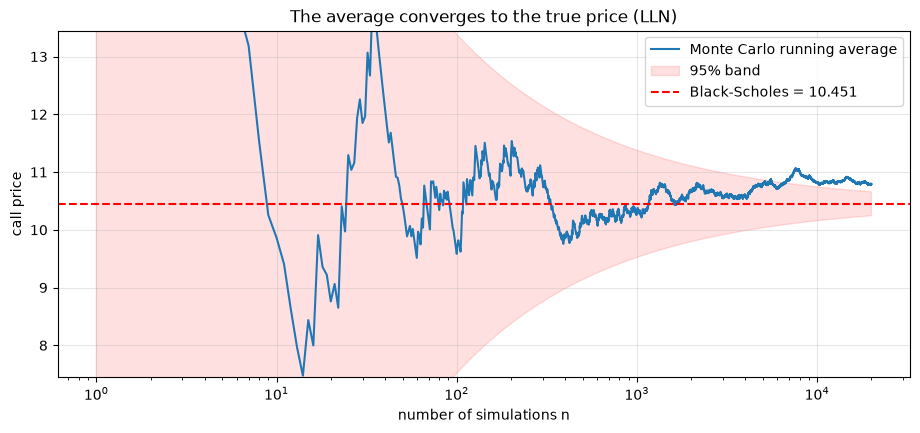

In [6]:
disc_payoffs = np.exp(-r * T) * payoff(ST[:20_000], K, "call")
n = np.arange(1, disc_payoffs.size + 1)
running_mean = np.cumsum(disc_payoffs) / n
band = 1.96 * disc_payoffs.std() / np.sqrt(n)
bs_call = black_scholes(S0, K, T, r, sigma, "call")

fig, ax = plt.subplots()
ax.plot(n, running_mean, label="Monte Carlo running average")
ax.fill_between(n, bs_call - band, bs_call + band, color="red", alpha=0.12, label="95% band")
ax.axhline(bs_call, color="red", ls="--", label=f"Black-Scholes = {bs_call:.3f}")
ax.set(xscale="log", ylim=(bs_call - 3, bs_call + 3), xlabel="number of simulations n", ylabel="call price",
       title="The average converges to the true price (LLN)")
ax.legend(); plt.show()

## 5. 4× more simulations → only 2× more accurate

Because $\text{SE} \propto 1/\sqrt N$, halving the error costs four times the work.
Check: for each $N$, price the call 500 times with fresh random numbers and measure how spread out the answers are.

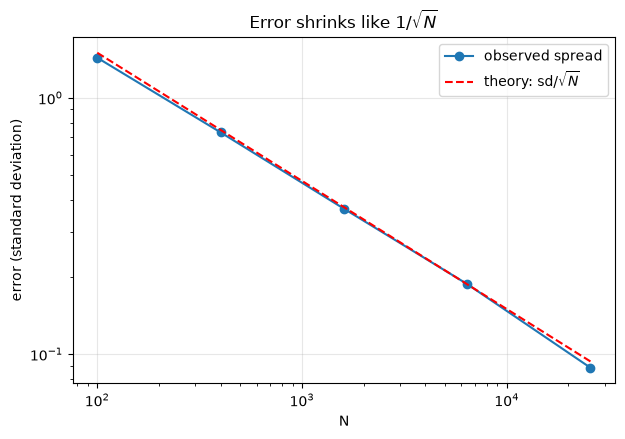

,sd of 500 estimates,theory sd/√N
N,,
100,1.4321,1.4981
400,0.7328,0.7490
1600,0.3692,0.3745
6400,0.1876,0.1873
25600,0.0885,0.0936


In [7]:
payoff_sd = disc_payoffs.std()
rows = []
for N in [100, 400, 1_600, 6_400, 25_600]:
    estimates = [monte_carlo(simulate_terminal_prices(S0, r, sigma, T, N, rng=rng), K, T, r)[0] for _ in range(500)]
    rows.append({"N": N, "sd of 500 estimates": np.std(estimates), "theory sd/√N": payoff_sd / np.sqrt(N)})
conv = pd.DataFrame(rows).set_index("N")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(conv.index, conv["sd of 500 estimates"], "o-", label="observed spread")
ax.loglog(conv.index, conv["theory sd/√N"], "r--", label=r"theory: sd$/\sqrt{N}$")
ax.set(xlabel="N", ylabel="error (standard deviation)", title="Error shrinks like $1/\\sqrt{N}$")
ax.legend(); plt.show()
conv

## 6. Different strikes, same simulations

One batch of simulated $S_T$ prices every option at once. Calls get cheaper as $K$ rises, puts get dearer.

In [8]:
table = price_table(ST, S0, strikes=[80, 90, 100, 110, 120], T=T, r=r, sigma=sigma)
table.pivot(index="strike", columns="kind", values=["mc_price", "bs_price"])

mc_price         bs_price        
kind         call     put     call     put
strike                                    
80.0000   24.5596  0.6971  24.5888  0.6872
90.0000   16.6759  2.3257  16.6994  2.3101
100.0000  10.4409  5.6030  10.4506  5.5735
110.0000   6.0570 10.7315   6.0401 10.6753
120.0000   3.2793 17.4660   3.2475 17.3950

## Takeaways

1. An option price is a **discounted expected payoff**.
2. Monte Carlo estimates that expectation with a **sample average** – it works because of the **LLN**.
3. The **CLT** tells us the error: $\text{SE} = \text{sd}/\sqrt N$, giving a 95% confidence interval.
4. Our simulation matches the exact Black–Scholes price, so the method is correct.
   Next notebook: does it match **real market prices**?